# ITAI 2376 — Midterm: Creating Images with Diffusion Models

**Student:** Monepha Mitchell  |  **Dataset:** Fashion-MNIST  |  **Environment:** Google Colab GPU

This notebook adapts the uploaded 21-cell reconstructed starting notebook into a reproducible experiment. It must be **run in Colab** before submission: cells currently contain code but not real training outcomes. Do not claim generated pictures, loss curves, or CLIP scores exist until executed.

**Order:** Run all required cells top to bottom; CLIP cells are optional. Notebook outputs, plots and checkpoints are saved under `midterm_outputs/`. If disconnected, download this folder and the executed `.ipynb`.

**Model reference:** Ho, Jain, & Abbeel (2020), https://arxiv.org/abs/2006.11239. Dataset: https://github.com/zalandoresearch/fashion-mnist. CLIP: Radford et al. (2021), https://proceedings.mlr.press/v139/radford21a.html.


## 1. Setup and imports

In [1]:
# Colab generally includes these packages; install einops if needed.
%pip -q install einops
import os, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from einops import rearrange

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)
if DEVICE.type != 'cuda':
    print('WARNING: Training on CPU will be slow. Enable a GPU in Colab.')

Using device: cuda


## 2. Configuration and diffusion schedule

In [2]:
IMG_SIZE = 28
IMG_CH = 1
N_CLASSES = 10
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 0.001
TIMESTEPS = 300  # Original example: 100; 300 provides a noisier terminal state.
BETA_START = 0.0001
BETA_END = 0.02
GRAD_CLIP = 1.0

betas = torch.linspace(BETA_START, BETA_END, TIMESTEPS, device=DEVICE)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)
print('Final alpha_bar:', float(alpha_bars[-1]))
OUTPUT_DIR = 'midterm_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)


Final alpha_bar: 0.0480584055185318


## 3. Forward and reverse diffusion

In [3]:
def add_noise(x0, t):
    noise = torch.randn_like(x0)
    a = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    b = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)
    return a * x0 + b * noise, noise

@torch.no_grad()
def remove_noise(x_t, t, model, cond, cond_mask):
    predicted_noise = model(x_t, t, cond, cond_mask)
    alpha_t = alphas[t].view(-1, 1, 1, 1)
    beta_t = betas[t].view(-1, 1, 1, 1)
    noise_scale = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)
    mean = (x_t - beta_t / noise_scale * predicted_noise) / torch.sqrt(alpha_t)
    # At t=0 return the predicted mean, not the still-noisy input.
    if torch.all(t == 0):
        return mean
    previous_alpha_bar = torch.where(t > 0, alpha_bars[(t - 1).clamp(min=0)], torch.ones_like(alpha_bars[t]))
    posterior_variance = beta_t * ((1 - previous_alpha_bar) / (1 - alpha_bars[t])).view(-1, 1, 1, 1)
    return mean + torch.sqrt(posterior_variance.clamp(min=0)) * torch.randn_like(x_t)

@torch.no_grad()
def sample_image(model, class_label, num_samples=1, capture_steps=None):
    model.eval()
    x = torch.randn(num_samples, IMG_CH, IMG_SIZE, IMG_SIZE, device=DEVICE)
    labels = torch.full((num_samples,), class_label, dtype=torch.long, device=DEVICE)
    cond = F.one_hot(labels, num_classes=N_CLASSES).float()
    cond_mask = torch.ones(num_samples, 1, device=DEVICE)
    snapshots = []
    capture_steps = set(capture_steps or [])
    for step in reversed(range(TIMESTEPS)):
        t = torch.full((num_samples,), step, device=DEVICE, dtype=torch.long)
        x = remove_noise(x, t, model, cond, cond_mask)
        if step in capture_steps:
            snapshots.append((step, x.detach().cpu().clone()))
    return ((x.clamp(-1, 1) + 1) / 2).cpu(), snapshots

## 4. U-Net architecture with time and class conditioning

In [4]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, group_size=8):
        super().__init__()
        while group_size > 1 and out_ch % group_size:
            group_size -= 1
        self.block = nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1),
                                   nn.GroupNorm(group_size, out_ch), nn.GELU())
    def forward(self, x):
        return self.block(x)

class DownSample(nn.Module):
    def __init__(self, in_ch, out_ch, group_size=8):
        super().__init__()
        self.conv1 = ConvBlock(in_ch, out_ch, group_size)
        self.conv2 = ConvBlock(out_ch, out_ch, group_size)
    def forward(self, x):
        x = self.conv2(self.conv1(x))
        return rearrange(x, 'b c (h r1) (w r2) -> b (c r1 r2) h w', r1=2, r2=2)

class UpSample(nn.Module):
    def __init__(self, in_ch, out_ch, skip_ch, group_size=8):
        super().__init__()
        self.upconv = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.conv1 = ConvBlock(out_ch + skip_ch, out_ch, group_size)
        self.conv2 = ConvBlock(out_ch, out_ch, group_size)
    def forward(self, x, skip):
        x = self.upconv(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv2(self.conv1(x))

class SinusoidalPositionEmbedBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        half_dim = self.dim // 2
        scale = math.log(10000.0) / (half_dim - 1)
        frequencies = torch.exp(torch.arange(half_dim, device=t.device) * -scale)
        emb = t.float()[:, None] * frequencies[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=1)

class TimeEmbedding(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.net = nn.Sequential(SinusoidalPositionEmbedBlock(embed_dim),
                                 nn.Linear(embed_dim, embed_dim), nn.GELU())
    def forward(self, t):
        return self.net(t)

class ClassEmbedding(nn.Module):
    def __init__(self, num_classes, embed_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(num_classes, embed_dim), nn.GELU(),
                                 nn.Linear(embed_dim, embed_dim))
    def forward(self, c):
        return self.net(c)

class DiffusionUNet(nn.Module):
    def __init__(self, T, img_ch, down_channels, time_embed_dim, num_classes):
        super().__init__()
        self.T = T
        self.time_embed = TimeEmbedding(time_embed_dim)
        self.class_embed = ClassEmbedding(num_classes, time_embed_dim)
        self.init_conv = ConvBlock(img_ch, down_channels[0])
        self.down1 = DownSample(down_channels[0], down_channels[1])
        self.down2 = DownSample(down_channels[1]*4, down_channels[2])
        bottleneck_channels = down_channels[2]*4
        self.bottleneck = nn.Sequential(ConvBlock(bottleneck_channels, bottleneck_channels),
                                        ConvBlock(bottleneck_channels, bottleneck_channels))
        self.cond_proj = nn.Sequential(nn.Linear(time_embed_dim, bottleneck_channels), nn.GELU())
        self.up1 = UpSample(bottleneck_channels, 64, down_channels[1]*4)
        self.up2 = UpSample(64, 32, down_channels[0])
        self.final_conv = nn.Conv2d(32, img_ch, 1)
    def forward(self, x, t, c, c_mask):
        t_emb = self.time_embed(t)
        # Apply the class mask, which was unused in the pasted version.
        c_emb = self.class_embed(c * c_mask)
        cond = self.cond_proj(t_emb + c_emb)[:, :, None, None]
        x0 = self.init_conv(x)
        x1 = self.down1(x0)
        x2 = self.down2(x1)
        x2 = self.bottleneck(x2) + cond
        x3 = self.up1(x2, x1)
        x4 = self.up2(x3, x0)
        return self.final_conv(x4)

DiffusionModel = DiffusionUNet
model = DiffusionModel(TIMESTEPS, IMG_CH, (32, 64, 128), 8, N_CLASSES).to(DEVICE)
with torch.no_grad():
    dummy = torch.randn(2, IMG_CH, IMG_SIZE, IMG_SIZE, device=DEVICE)
    labels = F.one_hot(torch.tensor([0, 5], device=DEVICE), N_CLASSES).float()
    result = model(dummy, torch.tensor([0, 10], device=DEVICE), labels, torch.ones(2, 1, device=DEVICE))
print('U-Net output shape:', tuple(result.shape))

U-Net output shape: (2, 1, 28, 28)


### Architecture smoke test
Confirm that U-Net dimensions and the noise process agree before training. This test uses synthetic tensors only.

In [5]:
assert tuple(result.shape) == (2, 1, 28, 28), 'U-Net output shape mismatch'
test_images = torch.randn(2, IMG_CH, IMG_SIZE, IMG_SIZE, device=DEVICE)
test_t = torch.tensor([0, TIMESTEPS - 1], device=DEVICE)
test_noisy, test_noise = add_noise(test_images, test_t)
assert test_noisy.shape == test_images.shape == test_noise.shape
assert torch.isfinite(test_noisy).all()
print('PASS: U-Net tensor shapes and forward diffusion smoke test')

PASS: U-Net tensor shapes and forward diffusion smoke test


## 5. Load Fashion-MNIST and split into training and validation sets

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 170kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.23MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.9MB/s]

Dataset loaded: 60000 samples (Train: 48000, Val: 12000)


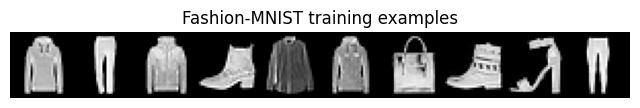

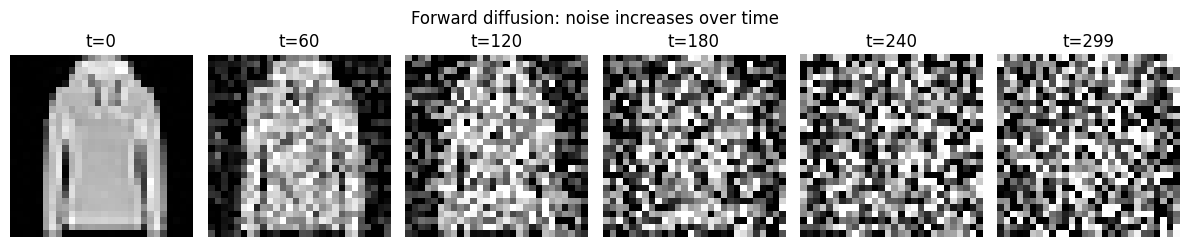

In [6]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
dataset = datasets.FashionMNIST(root='./data', train=True, transform=transform, download=True)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=(DEVICE.type == 'cuda'))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=(DEVICE.type == 'cuda'))
CLASS_NAMES = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
print(f'Dataset loaded: {len(dataset)} samples (Train: {train_size}, Val: {val_size})')
images, labels = next(iter(train_loader))
plt.figure(figsize=(8, 3))
plt.imshow(make_grid((images[:10] + 1) / 2, nrow=10).permute(1, 2, 0).squeeze(), cmap='gray')
plt.axis('off'); plt.title('Fashion-MNIST training examples'); plt.show()
# Forward diffusion visualization using a real dataset image.
example = images[:1].to(DEVICE)
steps = [0, TIMESTEPS // 5, 2*TIMESTEPS // 5, 3*TIMESTEPS // 5, 4*TIMESTEPS // 5, TIMESTEPS - 1]
fig, axes = plt.subplots(1, len(steps), figsize=(12, 2.5))
for ax, step in zip(axes, steps):
    noisy, _ = add_noise(example, torch.tensor([step], device=DEVICE))
    ax.imshow(((noisy[0,0].detach().cpu().clamp(-1,1) + 1)/2), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f't={step}'); ax.axis('off')
fig.suptitle('Forward diffusion: noise increases over time'); plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'forward_diffusion.png'), dpi=170, bbox_inches='tight')
plt.show()


## 6. Training and validation

**Training may take time.** Best validation checkpoints are saved to `/content/best_fashion_diffusion.pt` in Colab. Download the checkpoint if you need to preserve it beyond the session.

Starting training...


Epoch 1/30 train:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 1/30 val:   0%|          | 0/188 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f18453249a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7f18453249a0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():    
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
if w.is_alive():    assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError  File "/usr/lib/python3.13/multiprocessing/proce

Epoch 1/30 - Train Loss: 0.1160, Val Loss: 0.0931
Saved best checkpoint


Epoch 2/30 train:   0%|          | 0/750 [00:00<?, ?it/s]

... (122 outputs left out)

Epoch 30/30 train:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 30/30 val:   0%|          | 0/188 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f18453249a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7f18453249a0>
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    self._shutdown_workers()    if w.is_alive():

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
    assert self._parent_pid == os.getpid(), 'can only te

Epoch 30/30 - Train Loss: 0.0713, Val Loss: 0.0733


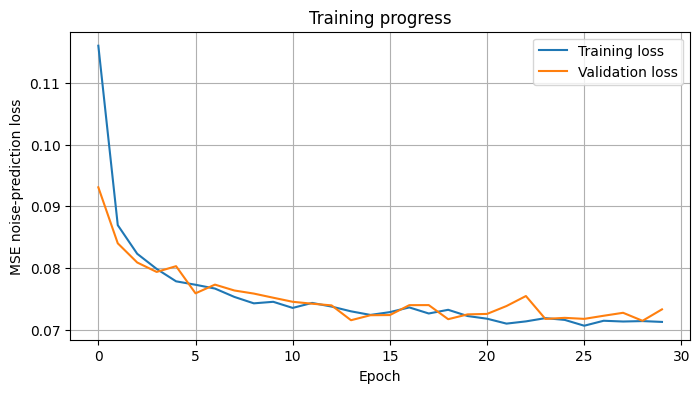

<Figure size 640x480 with 0 Axes>

Final train loss: 0.07128898639976979 Final val loss: 0.07332313453104902 Best val loss: 0.07146970311457172


In [7]:
def train_step(model, images, labels):
    c = F.one_hot(labels, num_classes=N_CLASSES).float()
    c_mask = torch.ones(labels.size(0), 1, device=DEVICE)
    t = torch.randint(0, TIMESTEPS, (images.size(0),), device=DEVICE)
    x_t, noise = add_noise(images, t)
    pred_noise = model(x_t, t, c, c_mask)
    return F.mse_loss(pred_noise, noise)

def train_model(model, train_loader, val_loader, optimizer, epochs):
    history = {'train': [], 'val': []}
    best_val_loss = float('inf')
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs} train', leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = train_step(model, images, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            train_loss += loss.item()
        avg_train_loss = train_loss / len(train_loader)
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc=f'Epoch {epoch+1}/{epochs} val', leave=False):
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                val_loss += train_step(model, images, labels).item()
        avg_val_loss = val_loss / len(val_loader)
        history['train'].append(avg_train_loss)
        history['val'].append(avg_val_loss)
        print(f'Epoch {epoch+1}/{epochs} - Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}')
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save({'epoch': epoch+1, 'model_state_dict': model.state_dict(),
                        'optimizer_state_dict': optimizer.state_dict(),
                        'train_loss': avg_train_loss, 'val_loss': avg_val_loss,
                        'timesteps': TIMESTEPS}, os.path.join(OUTPUT_DIR, 'best_fashion_diffusion.pt'))
            print('Saved best checkpoint')
    return history

optimizer = Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
print('Starting training...')
history = train_model(model, train_loader, val_loader, optimizer, EPOCHS)
plt.figure(figsize=(8, 4))
plt.plot(history['train'], label='Training loss')
plt.plot(history['val'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('MSE noise-prediction loss')
plt.legend(); plt.grid(True); plt.title('Training progress'); plt.show()
fig = plt.gcf()
fig.savefig(os.path.join(OUTPUT_DIR, 'training_losses.png'), dpi=170, bbox_inches='tight')
import json
plt.show()
with open(os.path.join(OUTPUT_DIR, 'training_history.json'), 'w') as f:
    json.dump({'train':history['train'], 'val':history['val'], 'epochs':EPOCHS,
               'timesteps':TIMESTEPS, 'dataset':'Fashion-MNIST'}, f, indent=2)
print('Final train loss:', history['train'][-1], 'Final val loss:', history['val'][-1],
      'Best val loss:', min(history['val']))


## 7. Generate images for all 10 Fashion-MNIST classes

Using checkpoint from epoch: 29


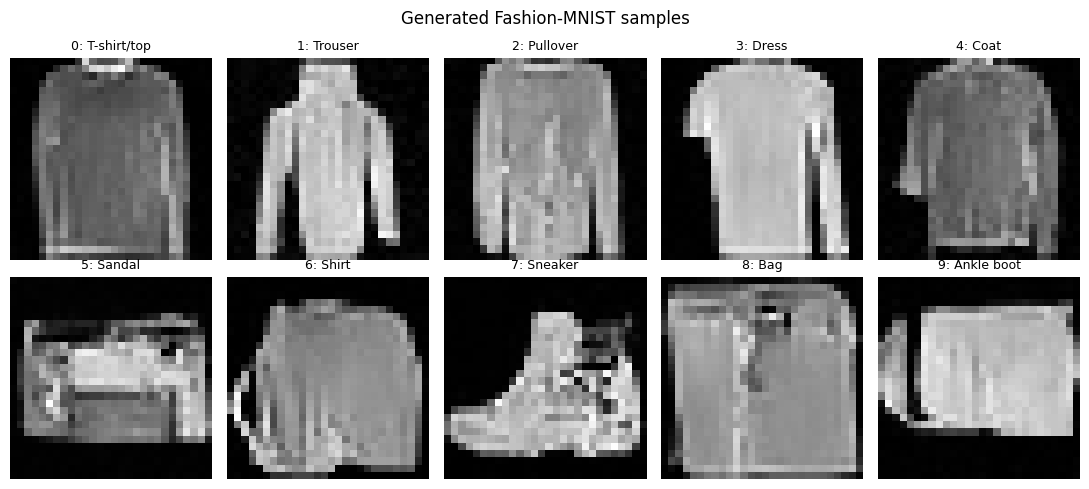

In [8]:
# Use the best validation checkpoint, rather than automatically using the last epoch.
checkpoint = torch.load(os.path.join(OUTPUT_DIR, 'best_fashion_diffusion.pt'), map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
print('Using checkpoint from epoch:', checkpoint['epoch'])

samples = []
for class_label in range(N_CLASSES):
    generated, _ = sample_image(model, class_label, num_samples=1)
    samples.append(generated)
samples = torch.cat(samples, dim=0)
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{i}: {CLASS_NAMES[i]}', fontsize=9)
    ax.axis('off')
plt.suptitle('Generated Fashion-MNIST samples'); plt.tight_layout(); plt.show()
fig.savefig(os.path.join(OUTPUT_DIR, 'generated_all_classes.png'), dpi=170, bbox_inches='tight')

plt.show()


## 8. Visualize the reverse diffusion process

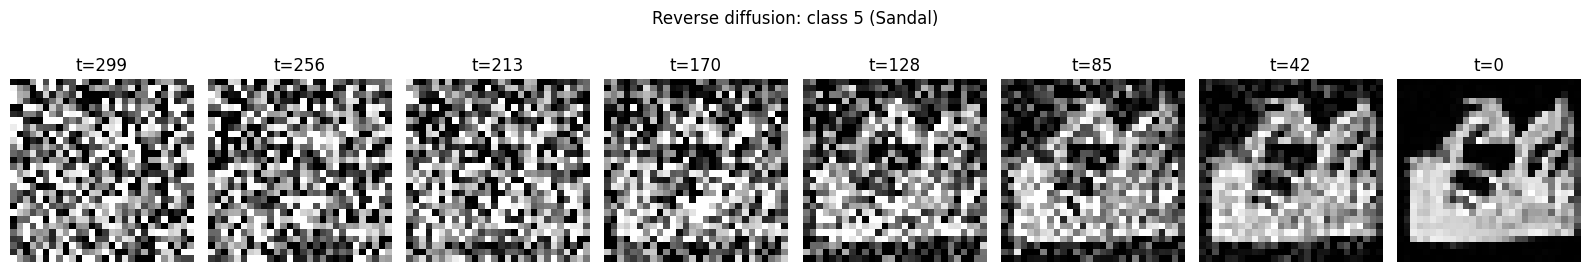

In [9]:
capture = sorted(set(np.linspace(TIMESTEPS - 1, 0, 8, dtype=int)), reverse=True)
final_sample, snapshots = sample_image(model, class_label=5, capture_steps=capture)
fig, axes = plt.subplots(1, len(snapshots), figsize=(16, 3))
for ax, (t, img) in zip(axes, snapshots):
    ax.imshow(((img[0, 0].clamp(-1, 1) + 1) / 2), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f't={t}')
    ax.axis('off')
plt.suptitle('Reverse diffusion: class 5 (Sandal)'); plt.tight_layout(); plt.show()
fig.savefig(os.path.join(OUTPUT_DIR, 'reverse_diffusion.png'), dpi=170, bbox_inches='tight')

plt.show()


## 9. Optional bonus: CLIP similarity evaluation

**Only run the following cells if you want the CLIP bonus.** CLIP compares images with text descriptions; similarity is **not** an accuracy percentage or a guarantee of realism. The model is trained on natural images and may be less informative for tiny grayscale Fashion-MNIST images.

In [10]:
# OPTIONAL: Run to install and load CLIP.
%pip -q install ftfy regex
%pip -q install git+https://github.com/openai/CLIP.git
import clip
clip_model, clip_preprocess = clip.load('ViT-B/32', device=DEVICE)
clip_model.eval()
print('CLIP loaded')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 216MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


CLIP loaded


CLIP cosine similarities: [0.2806290090084076, 0.2712213397026062, 0.30385905504226685, 0.26595476269721985, 0.2845563292503357]
Mean similarity: 0.28124409914016724


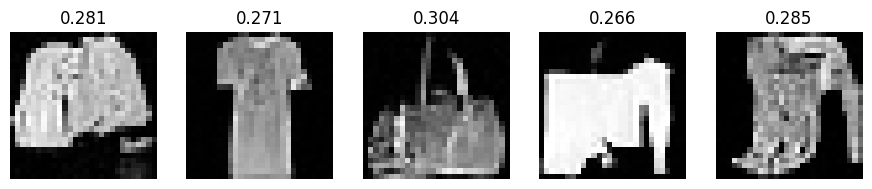

In [11]:
# OPTIONAL: Requires the preceding CLIP setup cell.
@torch.no_grad()
def evaluate_generated_images_clip(samples, class_name):
    # samples: [B, 1, 28, 28] in [0,1].
    from torchvision.transforms.functional import to_pil_image
    pil_images = [to_pil_image(img.cpu()) for img in samples]
    image_batch = torch.stack([clip_preprocess(img.convert('RGB')) for img in pil_images]).to(DEVICE)
    text = clip.tokenize([f'a grayscale image of a {class_name}']).to(DEVICE)
    image_features = clip_model.encode_image(image_batch)
    text_features = clip_model.encode_text(text)
    image_features = F.normalize(image_features.float(), dim=-1)
    text_features = F.normalize(text_features.float(), dim=-1)
    return (image_features @ text_features.T).squeeze(1).cpu()

class_label = 5
clip_samples, _ = sample_image(model, class_label, num_samples=5)
scores = evaluate_generated_images_clip(clip_samples, CLASS_NAMES[class_label])
print('CLIP cosine similarities:', scores.tolist())
print('Mean similarity:', scores.mean().item())
fig, axes = plt.subplots(1, 5, figsize=(11, 3))
for i, ax in enumerate(axes):
    ax.imshow(clip_samples[i, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{scores[i].item():.3f}'); ax.axis('off')
fig.savefig(os.path.join(OUTPUT_DIR, 'clip_evaluation.png'), dpi=170, bbox_inches='tight')
with open(os.path.join(OUTPUT_DIR, 'clip_scores.json'), 'w') as f:
    json.dump({'class': CLASS_NAMES[class_label], 'scores':scores.tolist(), 'mean':scores.mean().item()}, f, indent=2)

plt.show()


## 10. Observations based on executed outputs

- Completed all 30 training epochs on CUDA; final training/validation noise-prediction MSE: 0.0713 / 0.0733. Best validation MSE: 0.0715 at epoch 29.
- The sampled outputs often have clothing-like silhouettes, but not all outputs match their requested classes (e.g., the sample labeled Bag looks like trousers).
- Forward-noise images become difficult to identify around t=120 and effectively unrecognizable by t=180.
- Reverse-denoising the Sandal example yields an apparent shoe-like outline from roughly t=85 and a clearer sandal-like image by t=42 and t=0; this is a visual judgment, not an accuracy measurement.
- Five CLIP cosine similarities for sandal-class prompts: 0.2806, 0.2712, 0.3039, 0.2660, 0.2846 (mean 0.2812). The highest score belongs to a sample that visually resembles a bag, demonstrating that CLIP similarity alone should not be treated as proof of label fidelity.
- Intermittent DataLoader cleanup warnings appeared while the training continued; the full run completed and generated output images.


## Submission verification

Before submitting:
1. Run **Runtime > Run all** (or all required cells) in a Colab GPU session.
2. Check every non-optional code cell finishes without an exception.
3. Verify saved outputs: `training_history.json`, `training_losses.png`, `generated_all_classes.png`, `forward_diffusion.png`, `reverse_diffusion.png`, `best_fashion_diffusion.pt`.
4. Open the report PDF, replace the **RESULT REQUIRED** fields with actual losses/visual observations and include your actual figures.
5. Save/download the executed notebook and report. CLIP remains optional, but the written CLIP evaluation question must still be addressed, clearly stating if not run.

**Accuracy note:** Sample recognizability and score observations cannot be known before the GPU run.